# Módulo 3 — Regla del Punto Medio (prototipo en Python)

**Proyecto:** Cálculo Integral Interactivo · Matemáticas II · UTP

Implementamos la regla del punto medio **desde cero** y la comparamos con el trapecio.

$$M_n=\Delta x\sum_{i=1}^{n} f(\bar{x}_i),\qquad \bar{x}_i=\frac{x_{i-1}+x_i}{2},\qquad \Delta x=\frac{b-a}{n}$$

## 1. Preparación

In [1]:
# --- Bibliotecas que usaremos ---
import numpy as np                 # cálculo numérico con arreglos
import matplotlib.pyplot as plt    # gráficas
import sympy as sp                 # matemática simbólica: SOLO para el valor exacto y para verificar
                                   # (los algoritmos numéricos los escribimos nosotros desde cero)

x = sp.symbols("x")                # símbolo matemático "x" para SymPy

def preparar(expr, a, b):
    """Convierte una expresión de SymPy en (f_numpy, valor_exacto).
    - f_numpy: función que acepta arreglos de NumPy.
    - valor_exacto: integral definida exacta (Teorema Fundamental del Cálculo), como número decimal."""
    f = sp.lambdify(x, expr, "numpy")
    exacto = float(sp.integrate(expr, (x, a, b)))
    return f, exacto

## 2. Implementación desde cero

In [2]:
def punto_medio(f, a, b, n):
    """Regla del punto medio con n subintervalos."""
    dx = (b - a) / n
    centros = a + (np.arange(n) + 0.5) * dx      # el centro de cada franja
    return np.sum(f(centros)) * dx

def trapecio(f, a, b, n):
    """(Del cuaderno 2) Regla del trapecio; la usamos para comparar."""
    xs = np.linspace(a, b, n + 1)
    ys = f(xs)
    dx = (b - a) / n
    return dx / 2 * (ys[0] + 2 * np.sum(ys[1:-1]) + ys[-1])

## 3. Ejemplo 1 del módulo: $\int_0^1 e^x\,dx$ con $n=4$

In [3]:
f1, exacto1 = preparar(sp.exp(x), 0, 1)
M = punto_medio(f1, 0, 1, 4)
T = trapecio(f1, 0, 1, 4)
print(f"M4 = {M:.5f}   (a mano: 1.7138)")
print(f"T4 = {T:.5f}   (a mano: 1.7272)")
print(f"Exacto = e - 1 = {exacto1:.5f}")
print(f"error M4 = {abs(M - exacto1):.5f}   error T4 = {abs(T - exacto1):.5f}")
assert np.isclose(M, 1.7138, atol=1e-4) and np.isclose(T, 1.7272, atol=1e-4)
print("✔ Coincide con el ejemplo 1 del módulo 3")

M4 = 1.71382   (a mano: 1.7138)
T4 = 1.72722   (a mano: 1.7272)
Exacto = e - 1 = 1.71828
error M4 = 0.00447   error T4 = 0.00894
✔ Coincide con el ejemplo 1 del módulo 3


## 4. Ejemplo 2 del módulo: $\int_1^3 \dfrac{1}{x}\,dx$ con $n=4$

In [4]:
f2, exacto2 = preparar(1 / x, 1, 3)
M = punto_medio(f2, 1, 3, 4)
print(f"M4 = {M:.5f}   (a mano: 1.0898)")
print(f"ln 3 = {exacto2:.5f}   error = {abs(M - exacto2):.5f}")
assert np.isclose(M, 1.0898, atol=1e-4)
print("✔ Coincide con el ejemplo 2 del módulo 3")

M4 = 1.08975   (a mano: 1.0898)
ln 3 = 1.09861   error = 0.00886
✔ Coincide con el ejemplo 2 del módulo 3


## 5. Visualización: rectángulos y sus puntos medios

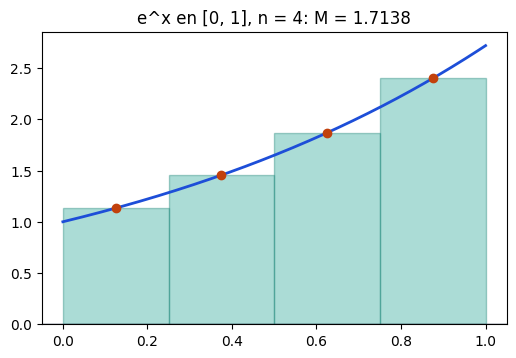

In [5]:
def dibujar_punto_medio(f, a, b, n, ax):
    xs = np.linspace(a, b, 400)
    ax.plot(xs, f(xs), lw=2, color="#1d4ed8")
    dx = (b - a) / n
    izq = a + np.arange(n) * dx
    centros = izq + dx / 2
    ax.bar(izq, f(centros), width=dx, align="edge",
           alpha=0.35, color="#0f9d8a", edgecolor="#0b7a6b")
    ax.plot(centros, f(centros), "o", color="#c2410c")      # los puntos medios
    ax.axhline(0, color="#14213d", lw=1)

fig, ax = plt.subplots(figsize=(6, 3.8))
dibujar_punto_medio(f1, 0, 1, 4, ax)
ax.set_title(f"e^x en [0, 1], n = 4: M = {punto_medio(f1, 0, 1, 4):.4f}")
plt.show()

## 6. Errores CON SIGNO: punto medio frente a trapecio
Definimos el error con signo como *aproximación − exacto*. Positivo = sobreestima; negativo = subestima.

In [6]:
ns = [2, 4, 8, 16, 32, 64, 128]
print(f"{'n':>5} | {'error M':>12} | {'error T':>12} | {'E_T / E_M':>10}")
print("-" * 50)
for n in ns:
    eM = punto_medio(f1, 0, 1, n) - exacto1
    eT = trapecio(f1, 0, 1, n) - exacto1
    print(f"{n:>5} | {eM:>12.3e} | {eT:>12.3e} | {eT / eM:>10.3f}")

    n |      error M |      error T |  E_T / E_M
--------------------------------------------------
    2 |   -1.777e-02 |    3.565e-02 |     -2.006
    4 |   -4.467e-03 |    8.940e-03 |     -2.002
    8 |   -1.118e-03 |    2.237e-03 |     -2.000
   16 |   -2.796e-04 |    5.593e-04 |     -2.000
   32 |   -6.992e-05 |    1.398e-04 |     -2.000
   64 |   -1.748e-05 |    3.496e-05 |     -2.000
  128 |   -4.370e-06 |    8.740e-06 |     -2.000


## 7. Comparación en escala logarítmica

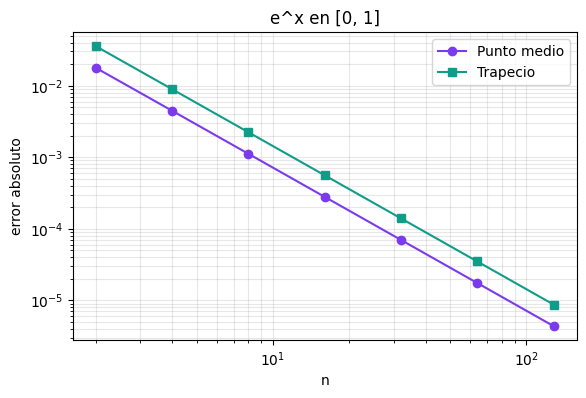

In [7]:
errM = [abs(punto_medio(f1, 0, 1, n) - exacto1) for n in ns]
errT = [abs(trapecio(f1, 0, 1, n) - exacto1) for n in ns]

plt.figure(figsize=(6.5, 4))
plt.loglog(ns, errM, "o-", label="Punto medio", color="#7c3aed")
plt.loglog(ns, errT, "s-", label="Trapecio", color="#0f9d8a")
plt.xlabel("n"); plt.ylabel("error absoluto")
plt.title("e^x en [0, 1]")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

## Preguntas para pensar

1. Mira la columna $E_T/E_M$ de la tabla. ¿Cerca de qué número se estabiliza? ¿Y qué signo tiene? ¿Qué te dice eso sobre uno y otro método?
2. ¿Por qué el punto medio **subestima** $e^x$ mientras el trapecio la **sobreestima**? Piensa en la concavidad y en dónde queda la curva respecto de la recta o del rectángulo dentro de cada franja.
3. **Ejercicio:** repite la tabla con $f(x)=\operatorname{sen}(x)$ en $[0,\pi]$ (`preparar(sp.sin(x), 0, sp.pi)`; recuerda pasar `float(sp.pi)` como límite superior a las funciones numéricas). ¿Cambian los signos? ¿Por qué?